# The Mathematics of Pricing and Discounts
### A Python-Based Analysis of How Discounts Affect Revenue and Profitability

**Project type:** Math application  
**Level:** Beginner  
**Currency:** EUR

## 1. Introduction

Businesses often use discounts to encourage customers to buy products. However, a discount reduces the selling price, which can affect revenue and profit.

This project uses simple mathematical formulas and Python to explore how different discount rates affect the financial results of a small fictional product catalogue.

All data in this project is fictional and created for educational purposes.

## 2. Problem Formulation

**Research question:** How do different discount rates affect revenue and profit?

We will compare three discount scenarios:

- Scenario A: 0% discount
- Scenario B: 10% discount
- Scenario C: 20% discount

For the first version, we will keep the quantity sold constant across scenarios. This is an important assumption: it allows us to isolate the direct mathematical effect of changing the selling price. Later, we can discuss how real customer demand might change when prices change.

## 3. Mathematical Background

Let:

- `P` = original selling price per unit
- `d` = discount rate, expressed as a decimal
- `C` = cost per unit
- `Q` = quantity sold

### 3.1 Discounted selling price

\[
P_d = P(1-d)
\]

### 3.2 Revenue

\[
Revenue = P_d \times Q
\]

### 3.3 Total profit

\[
Profit = (P_d-C)\times Q
\]

### 3.4 Profit margin

\[
Profit\ Margin = \frac{Profit}{Revenue}\times 100
\]

The profit margin is only meaningful when revenue is greater than zero.

## 4. Dataset Description

We will work with three fictional products. The dataset contains the original selling price, unit cost, and quantity sold.

The quantity is held constant in all discount scenarios. This is a simplifying assumption, not a prediction of real customer behaviour.

In [1]:
# Import the pandas library to work with tabular data
import pandas as pd

# Create a small fictional dataset
products = {
    "Product": ["Printer", "Toner", "Paper"],
    "Original_Price": [250.00, 80.00, 12.00],
    "Unit_Cost": [170.00, 45.00, 7.00],
    "Quantity_Sold": [20, 50, 200]
}

# Convert the dictionary into a DataFrame
df = pd.DataFrame(products)

# Display the dataset
df

,Product,Original_Price,Unit_Cost,Quantity_Sold
0,Printer,250.0,170.0,20
1,Toner,80.0,45.0,50
2,Paper,12.0,7.0,200


### 4.1 First observations

Before applying discounts, inspect the data:

- Which product has the highest original selling price?
- Which product has the highest quantity sold?
- What is the difference between the selling price and unit cost?

Try to answer these questions using the table before moving to the next section.

**Observations:**

- Printer has the highest original selling price at 250 EUR.
- Paper has the highest quantity sold at 200 units.
- The unit profit before discounts is 80 EUR for Printer, 35 EUR for Toner, and 5 EUR for Paper.

In [2]:
# Calculate the profit earned on one unit before any discount
df["Unit_Profit_Before_Discount"] = df["Original_Price"] - df["Unit_Cost"]

# Calculate total revenue and total profit before discounts
df["Revenue_Before_Discount"] = df["Original_Price"] * df["Quantity_Sold"]
df["Profit_Before_Discount"] = df["Unit_Profit_Before_Discount"] * df["Quantity_Sold"]

df

,Product,Original_Price,Unit_Cost,Quantity_Sold,Unit_Profit_Before_Discount,Revenue_Before_Discount,Profit_Before_Discount
0,Printer,250.0,170.0,20,80.0,5000.0,1600.0
1,Toner,80.0,45.0,50,35.0,4000.0,1750.0
2,Paper,12.0,7.0,200,5.0,2400.0,1000.0


## 5. Discount Scenarios

In this section, we will analyze how different discount rates affect revenue and profitability.

We will compare three scenarios:
- 0% discount
- 10% discount
- 20% discount

The quantity sold will remain constant in all scenarios.

In [3]:
discount_rates = [0, 0.10, 0.20]

discount_rates

[0, 0.1, 0.2]

In [4]:
for discount in discount_rates:
    df[f"Price_After_{int(discount * 100)}_Percent"] = (
        df["Original_Price"] * (1 - discount)
    )

df

,Product,Original_Price,Unit_Cost,Quantity_Sold,Unit_Profit_Before_Discount,Revenue_Before_Discount,Profit_Before_Discount,Price_After_0_Percent,Price_After_10_Percent,Price_After_20_Percent
0,Printer,250.0,170.0,20,80.0,5000.0,1600.0,250.0,225.0,200.0
1,Toner,80.0,45.0,50,35.0,4000.0,1750.0,80.0,72.0,64.0
2,Paper,12.0,7.0,200,5.0,2400.0,1000.0,12.0,10.8,9.6


In [5]:
for discount in discount_rates:
    column_name = f"Revenue_After_{int(discount * 100)}_Percent"
    price_column = f"Price_After_{int(discount * 100)}_Percent"

    df[column_name] = df[price_column] * df["Quantity_Sold"]

df

,Product,Original_Price,Unit_Cost,Quantity_Sold,Unit_Profit_Before_Discount,Revenue_Before_Discount,Profit_Before_Discount,Price_After_0_Percent,Price_After_10_Percent,Price_After_20_Percent,Revenue_After_0_Percent,Revenue_After_10_Percent,Revenue_After_20_Percent
0,Printer,250.0,170.0,20,80.0,5000.0,1600.0,250.0,225.0,200.0,5000.0,4500.0,4000.0
1,Toner,80.0,45.0,50,35.0,4000.0,1750.0,80.0,72.0,64.0,4000.0,3600.0,3200.0
2,Paper,12.0,7.0,200,5.0,2400.0,1000.0,12.0,10.8,9.6,2400.0,2160.0,1920.0


In [6]:
for discount in discount_rates:
    column_name = f"Profit_After_{int(discount * 100)}_Percent"
    price_column = f"Price_After_{int(discount * 100)}_Percent"

    df[column_name] = (
        (df[price_column] - df["Unit_Cost"])
        * df["Quantity_Sold"]
    )

df

,Product,Original_Price,Unit_Cost,Quantity_Sold,Unit_Profit_Before_Discount,Revenue_Before_Discount,Profit_Before_Discount,Price_After_0_Percent,Price_After_10_Percent,Price_After_20_Percent,Revenue_After_0_Percent,Revenue_After_10_Percent,Revenue_After_20_Percent,Profit_After_0_Percent,Profit_After_10_Percent,Profit_After_20_Percent
0,Printer,250.0,170.0,20,80.0,5000.0,1600.0,250.0,225.0,200.0,5000.0,4500.0,4000.0,1600.0,1100.0,600.0
1,Toner,80.0,45.0,50,35.0,4000.0,1750.0,80.0,72.0,64.0,4000.0,3600.0,3200.0,1750.0,1350.0,950.0
2,Paper,12.0,7.0,200,5.0,2400.0,1000.0,12.0,10.8,9.6,2400.0,2160.0,1920.0,1000.0,760.0,520.0


In [7]:
for discount in discount_rates:
    margin_column = f"Profit_Margin_{int(discount * 100)}_Percent"
    revenue_column = f"Revenue_After_{int(discount * 100)}_Percent"
    profit_column = f"Profit_After_{int(discount * 100)}_Percent"

    df[margin_column] = (
        df[profit_column] / df[revenue_column] * 100
    )

df

,Product,Original_Price,Unit_Cost,Quantity_Sold,Unit_Profit_Before_Discount,Revenue_Before_Discount,Profit_Before_Discount,Price_After_0_Percent,Price_After_10_Percent,Price_After_20_Percent,Revenue_After_0_Percent,Revenue_After_10_Percent,Revenue_After_20_Percent,Profit_After_0_Percent,Profit_After_10_Percent,Profit_After_20_Percent,Profit_Margin_0_Percent,Profit_Margin_10_Percent,Profit_Margin_20_Percent
0,Printer,250.0,170.0,20,80.0,5000.0,1600.0,250.0,225.0,200.0,5000.0,4500.0,4000.0,1600.0,1100.0,600.0,32.000000,24.444444,15.000000
1,Toner,80.0,45.0,50,35.0,4000.0,1750.0,80.0,72.0,64.0,4000.0,3600.0,3200.0,1750.0,1350.0,950.0,43.750000,37.500000,29.687500
2,Paper,12.0,7.0,200,5.0,2400.0,1000.0,12.0,10.8,9.6,2400.0,2160.0,1920.0,1000.0,760.0,520.0,41.666667,35.185185,27.083333


In [8]:
summary = []

for discount in discount_rates:
    revenue_column = f"Revenue_After_{int(discount * 100)}_Percent"
    profit_column = f"Profit_After_{int(discount * 100)}_Percent"

    summary.append({
        "Discount": f"{int(discount * 100)}%",
        "Total_Revenue": df[revenue_column].sum(),
        "Total_Profit": df[profit_column].sum()
    })

summary_df = pd.DataFrame(summary)

summary_df

,Discount,Total_Revenue,Total_Profit
0,0%,11400.0,4350.0
1,10%,10260.0,3210.0
2,20%,9120.0,2070.0


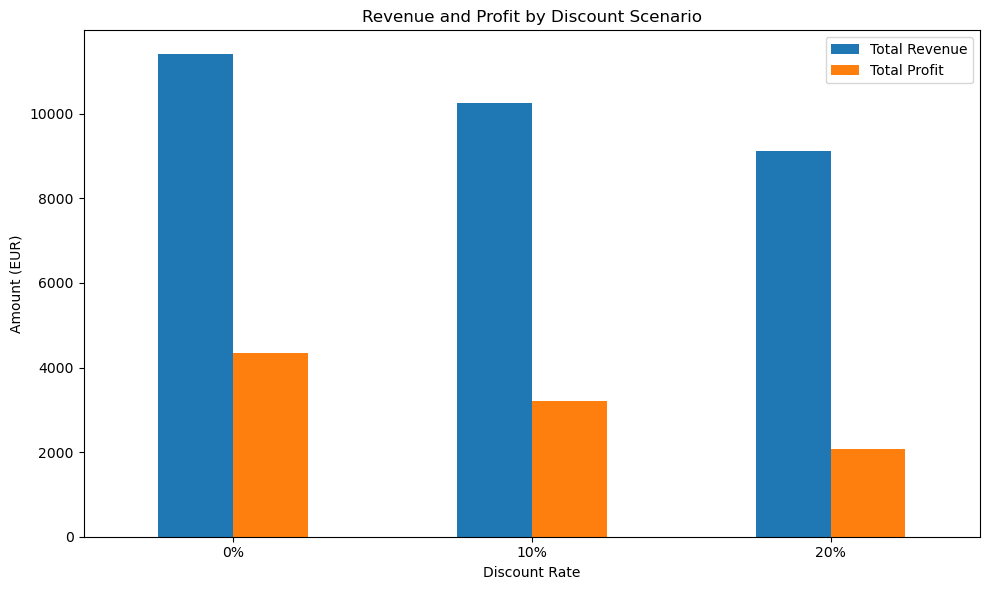

In [9]:
import matplotlib.pyplot as plt

summary_df.plot(
    x="Discount",
    y=["Total_Revenue", "Total_Profit"],
    kind="bar",
    figsize=(10, 6),
    title="Revenue and Profit by Discount Scenario"
)

plt.ylabel("Amount (EUR)")
plt.xlabel("Discount Rate")
plt.xticks(rotation=0)
plt.legend(["Total Revenue", "Total Profit"])
plt.tight_layout()
plt.show()

In [10]:
# Validate the calculated financial results

assert summary_df.loc[0, "Total_Revenue"] == 11400
assert summary_df.loc[0, "Total_Profit"] == 4350

assert summary_df.loc[1, "Total_Revenue"] == 10260
assert summary_df.loc[1, "Total_Profit"] == 3210

assert summary_df.loc[2, "Total_Revenue"] == 9120
assert summary_df.loc[2, "Total_Profit"] == 2070

print("All financial calculations have been validated successfully.")

All financial calculations have been validated successfully.


## 6. Analysis and Discussion

The results show that discounts have a negative impact on both revenue and total profit when the quantity sold remains constant.

Without a discount, total revenue is 11,400 EUR and total profit is 4,350 EUR.

With a 10% discount, total revenue decreases to 10,260 EUR and total profit decreases to 3,210 EUR.

With a 20% discount, total revenue decreases to 9,120 EUR and total profit decreases to 2,070 EUR.

The analysis shows that profit decreases faster than revenue because the unit cost remains unchanged while the selling price is reduced.

**Limitations:**

The analysis assumes that the quantity sold remains constant regardless of the discount rate. In a real business situation, lower prices may increase demand. This effect is not included in our model.

### Financial Impact of a 20% Discount

Compared to the 0% discount scenario, the 20% discount scenario reduces total profit by 2,280 EUR.

The percentage decrease in profit is:

(4,350 - 2,070) / 4,350 × 100 = 52.4%

This means that a 20% discount leads to a 52.4% decrease in total profit when the quantity sold remains constant.

This demonstrates that a discount percentage does not necessarily translate into the same percentage decrease in profit.

### Percentage Change Compared to the Baseline

The following table shows the percentage decrease in revenue and profit compared to the scenario without a discount.

| Discount | Revenue Decrease | Profit Decrease |
|---|---:|---:|
| 0% | 0% | 0% |
| 10% | 10% | 26.2% |
| 20% | 20% | 52.4% |

The results demonstrate that profit is more sensitive to discounts than revenue. A 10% discount reduces profit by 26.2%, while a 20% discount reduces it by 52.4%, assuming that the quantity sold remains constant.

## 7. Conclusion

This project demonstrates how discount rates affect revenue and profitability.

The analysis shows that increasing discounts reduces both total revenue and total profit when the quantity sold remains constant.

The 0% discount scenario generates the highest total profit of 4,350 EUR.

The 10% discount scenario generates a total profit of 3,210 EUR, while the 20% discount scenario generates only 2,070 EUR.

The results suggest that businesses should carefully evaluate discount strategies before applying them.

In future analysis, the model could be improved by including changes in customer demand and sales volume in response to lower prices.

## 8. References

1. Python Software Foundation. Python Documentation.
   https://docs.python.org/3/

2. pandas Development Team. pandas Documentation.
   https://pandas.pydata.org/docs/

3. Matplotlib Development Team. Matplotlib Documentation.
   https://matplotlib.org/stable/

4. Course materials: Math for Developers.